In [1]:
import pandas as pd
import numpy as np
print("My CodeAlpha EDA project has started!")
from google.colab import files
uploaded = files.upload()
df = pd.read_excel("Online Retail.xlsx")
print("Dataset shape:", df.shape)
display(df.head())

My CodeAlpha EDA project has started!


Saving Online Retail.xlsx to Online Retail.xlsx
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Check column names
print("Column names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical summary:")
display(df.describe())

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
C

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [4]:
# Step 3: Clean the retail dataset

# Keep the original data unchanged
clean_df = df.copy()

# 1. Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# 2. Remove rows missing essential fields
clean_df = clean_df.dropna(
    subset=["InvoiceNo", "Description", "InvoiceDate",
            "Quantity", "UnitPrice", "Country"]
)

# 3. Exclude cancelled invoices
clean_df = clean_df[
    ~clean_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# 4. Keep positive quantities and prices for sales analysis
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

# 5. Calculate revenue for each transaction line
clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# Display the results
print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
print("Remaining missing values:", clean_df.isnull().sum().sum())

display(clean_df.head())

Original dataset rows: 541909
Cleaned dataset rows: 524878
Rows removed: 17031
Remaining missing values: 132186


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [5]:
# Overall sales analysis

print("Total Revenue:", round(clean_df["Revenue"].sum(), 2))
print("Unique Invoices:", clean_df["InvoiceNo"].nunique())
print("Unique Products:", clean_df["StockCode"].nunique())
print("Unique Countries:", clean_df["Country"].nunique())

# Top 10 countries by revenue
country_sales = (
    clean_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTop 10 Countries by Revenue:")
display(country_sales.head(10).to_frame())

# Top 10 products by revenue
product_sales = (
    clean_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTop 10 Products by Revenue:")
display(product_sales.head(10).to_frame())

Total Revenue: 10642110.8
Unique Invoices: 19960
Unique Products: 3922
Unique Countries: 38

Top 10 Countries by Revenue:


,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340



Top 10 Products by Revenue:


,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


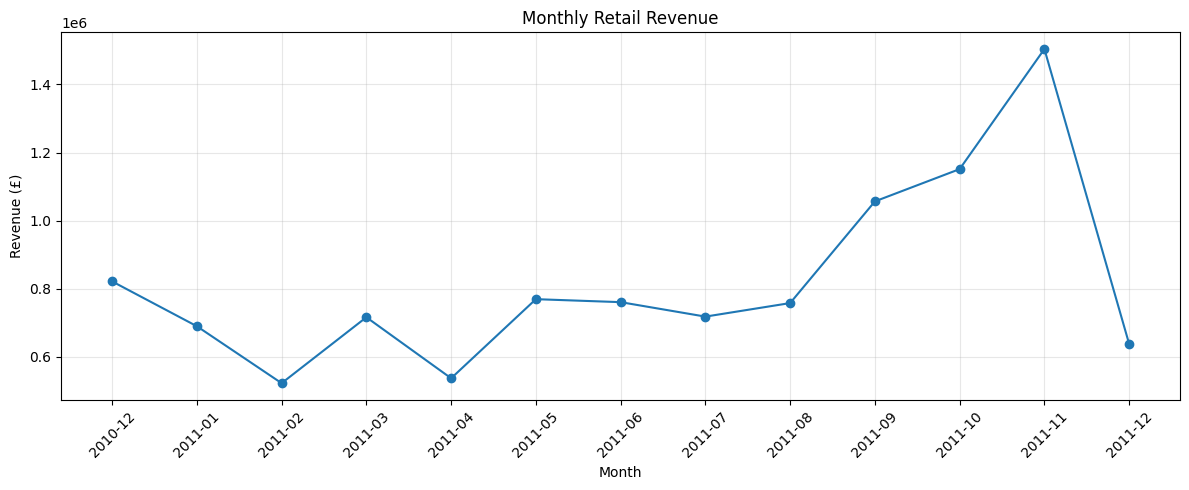

In [6]:
import matplotlib.pyplot as plt

# Calculate monthly revenue
clean_df["YearMonth"] = (
    clean_df["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    clean_df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Plot monthly revenue
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig("monthly_revenue.png", dpi=150)
plt.show()

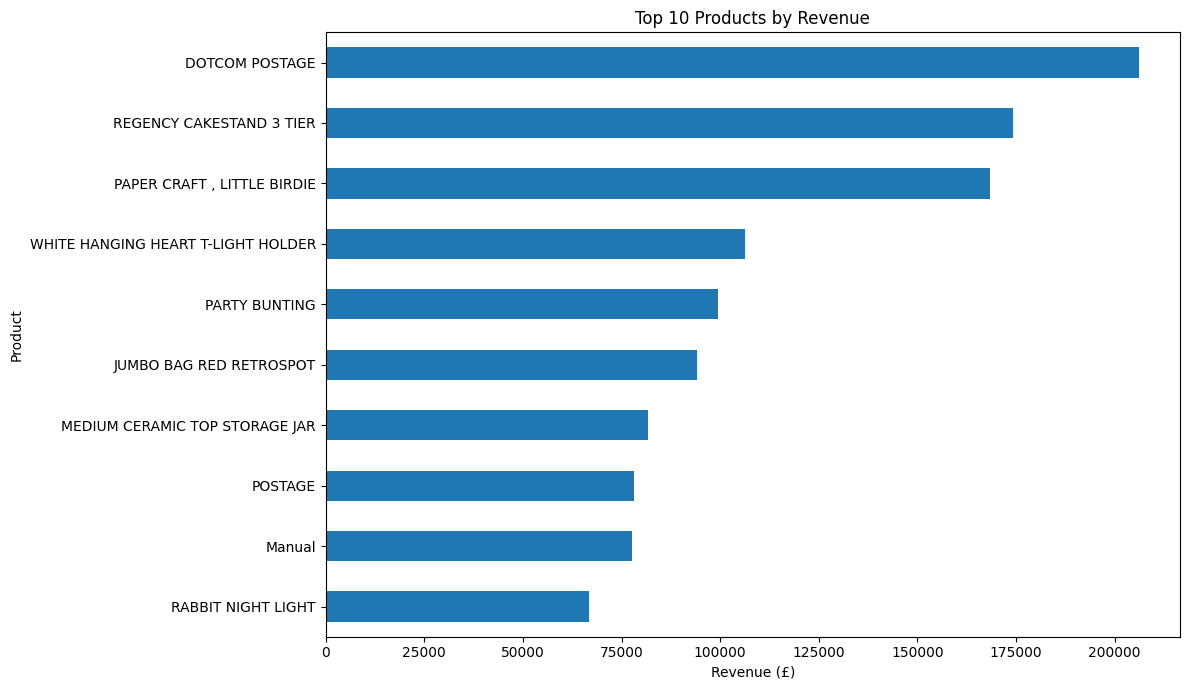

In [7]:
import matplotlib.pyplot as plt

# Calculate revenue by product
top_products = (
    clean_df.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

top_products.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()

# Save the chart
plt.savefig("top_10_products.png", dpi=150)
plt.show()

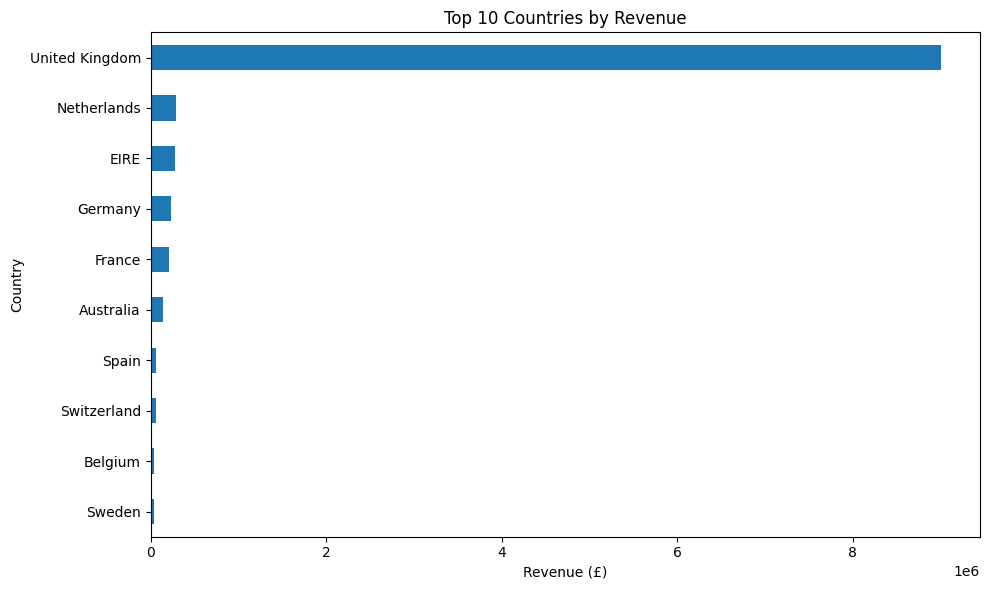

In [8]:
import matplotlib.pyplot as plt

# Calculate revenue by country
top_countries = (
    clean_df.groupby("Country")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

# Save chart
plt.savefig("top_10_countries.png", dpi=150)
plt.show()

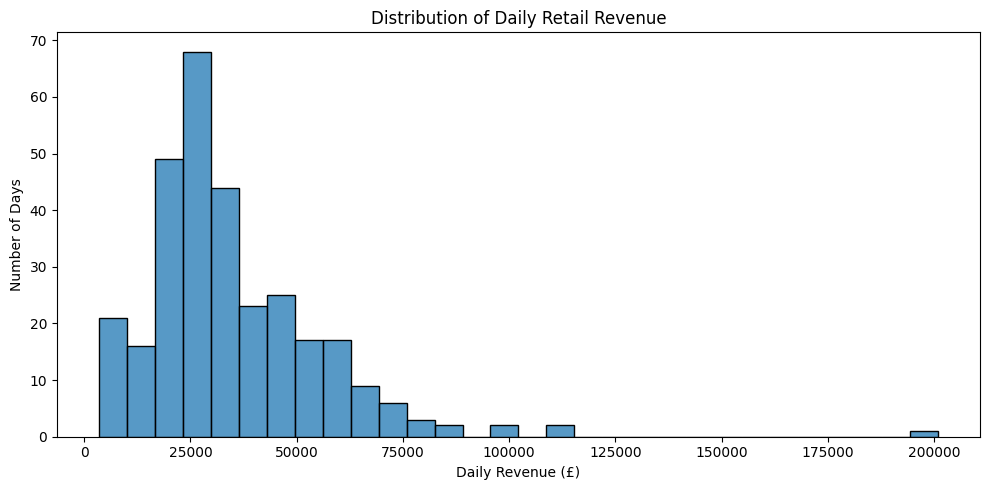

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate daily revenue
clean_df["Date"] = clean_df["InvoiceDate"].dt.date

daily_sales = clean_df.groupby("Date")["Revenue"].sum()

# Plot the distribution
plt.figure(figsize=(10, 5))

sns.histplot(daily_sales, bins=30)

plt.title("Distribution of Daily Retail Revenue")
plt.xlabel("Daily Revenue (£)")
plt.ylabel("Number of Days")
plt.tight_layout()

plt.savefig("daily_revenue_distribution.png", dpi=150)
plt.show()

In [10]:

from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

# Save cleaned data
clean_df.to_csv(
    "outputs/cleaned_retail_data.csv",
    index=False
)

# Save analysis summaries
country_sales.to_csv("outputs/country_sales.csv")
product_sales.to_csv("outputs/product_sales.csv")
monthly_sales.to_csv("outputs/monthly_sales.csv")

print("All datasets and summaries saved successfully.")
from google.colab import files

files.download("outputs/cleaned_retail_data.csv")

All datasets and summaries saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>